# Focusing through a diffuser: in situ training of the object arm

Digital twin of the off-axis holography bench of the manuscript. A phase-only SLM writes the object pattern
$X_O = e^{j\theta}$ on $32\times32$ cells; the light crosses a ground-glass diffuser and meets a tilted reference beam
on the camera. One camera frame gives the complex field $\hat O$, so the error field of every gradient is **measured**;
only the adjoint, which carries it back to the SLM, comes from a model.

| Section | In the manuscript |
|---|---|
| 1 · One hologram gives the complex field | Methods "Measuring the complex field"; Supplementary Note 1B, Fig. S1 |
| 2 · The holographic gradient | Eqs. (2)–(3); Supplementary Note 2A |
| 3 · Physical model fitted from probes | Eqs. (4)–(5); Fig. 2b; Supplementary Note 3A |
| 4 · In situ focusing, model vs transmission matrix | Fig. 2c,d; Supplementary Notes 3B–C |
| 5 · Single-step focus from each adjoint | Supplementary Note 3C |
| 6 · A stored TM ages; the model is refitted | Supplementary Note 3C; Methods |
| 7 · Focusing while the diffuser drifts slowly | Fig. 4a; Methods; Supplementary Note 5A |

The optics, the bench and the methods shared by all notebooks are in [`twin.py`](twin.py); this notebook shows the
steps of the experiment. The twin hides the true diffuser and the lens aberrations from every method and adds the
noise of the bench, so its numbers are close to, but not the same as, those measured on the bench.
Every training run is saved as a GIF in `gifs/` (measured intensity per iteration next to the enhancement).
Runtime about 5 min on a laptop CPU.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from IPython.display import Image, display
import twin as tw

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
os.makedirs("gifs", exist_ok=True)
T_START = time.time()

## 1 · One hologram gives the complex field

The camera records $I = |O+R|^2 = |O|^2 + |R|^2 + OR^* + O^*R$. The reference is tilted, so the interference term sits
on a spatial carrier; cropping it in the Fourier domain, shifting it to zero and dividing by the reference gives
$\hat O$, amplitude and phase, from one frame. The **focusing bench** is dim (reference 200, object 2 counts per pixel)
so that the focus does not saturate the 12-bit camera.

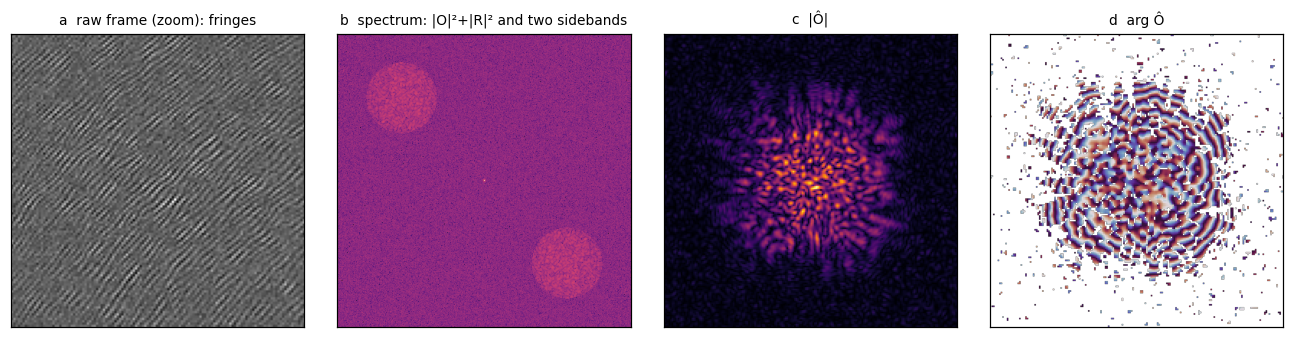

noise-free round trip hologram -> demodulation: relative error 2.4e-06
repeatability (correlation): one exposure vs another 0.75, one exposure vs mean of ten 0.84


In [2]:
bench = tw.Bench("focus", seed=0)
rng = np.random.default_rng(7)
X = tw.random_patterns(rng, 1)[0]
frame = bench.frame(X)
O_hat = tw.demodulate(frame, bench.r0)

c, z = tw.NU // 2, 64
spectrum = np.log10(np.abs(np.fft.fftshift(np.fft.fft2(frame)))**2 + 1)
amp = np.abs(O_hat)
fig, ax = plt.subplots(1, 4, figsize=(12, 3))
ax[0].imshow(frame[c - z:c + z, c - z:c + z], cmap="gray"); ax[0].set_title("a  raw frame (zoom): fringes")
ax[1].imshow(spectrum, cmap="magma"); ax[1].set_title("b  spectrum: |O|²+|R|² and two sidebands")
ax[2].imshow(amp, cmap="inferno"); ax[2].set_title("c  |Ô|")
ax[3].imshow(np.where(amp > 0.1 * amp.max(), np.angle(O_hat), np.nan), cmap="twilight"); ax[3].set_title("d  arg Ô")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

O = tw.ObjectArm(tw.random_screen(rng)).forward(X)
print(f"noise-free round trip hologram -> demodulation: relative error "
      f"{np.linalg.norm(tw.demodulate(tw.hologram(O, 14.0), 14.0) - O) / np.linalg.norm(O):.1e}")
one, ten = bench.read(X, 1), bench.read(X, 10)
print(f"repeatability (correlation): one exposure vs another {tw.corr(one, bench.read(X, 1)):.2f}, "
      f"one exposure vs mean of ten {tw.corr(one, ten):.2f}")

## 2 · The holographic gradient

For a real loss $L$ of the measured intensity, Wirtinger calculus gives the error field and the gradient of the
object arm,

$$W = \frac{\partial L}{\partial O^*} = g\odot\hat O,\quad g=\frac{\partial L}{\partial|\hat O|^2},\qquad
\frac{\partial L}{\partial\theta} = 2\,\mathrm{Im}\big[X_O^*\odot T_O^{\mathrm H}\{W\}\big].\qquad\text{(Eqs. 2–3)}$$

$\hat O$ is the measured field; only the adjoint $T_O^{\mathrm H}$ is modelled. Each frame carries one unknown complex
factor (phase between the arms, pulse energy), removed with one phase per frame from the model's forward prediction
(Supplementary Eq. S12, `tw.to_model_gauge`). Below, the adjoint and the gradient are checked against finite
differences on a random instance (Supplementary Note 2A: relative error below $10^{-8}$).

In [3]:
arm = tw.ObjectArm(tw.random_screen(rng), tw.ABERRATION)       # any linear arm
theta = rng.random((tw.NC, tw.NC)) * 2 * np.pi
Y = tw.ifft2(tw.fft2(rng.standard_normal((tw.N, tw.N)) + 0j) * tw.BAND)
lhs, rhs = np.vdot(arm.forward(np.exp(1j * theta)), Y), np.vdot(np.exp(1j * theta), arm.adjoint(Y))
print(f"adjoint: |<T x, y> - <x, T^H y>| / |<T x, y>| = {abs(lhs - rhs) / abs(lhs):.1e}")

loss_of = lambda th: tw.focus_loss(np.abs(arm.forward(np.exp(1j * th)))**2)[0]
X = np.exp(1j * theta)
O = arm.forward(X)
grad = tw.object_gradient(X, tw.focus_loss(np.abs(O)**2)[1] * O, arm)          # Eq. (3)
for _ in range(3):
    d, h = rng.standard_normal(theta.shape), 1e-5
    fd = (loss_of(theta + h * d) - loss_of(theta - h * d)) / (2 * h)
    print(f"gradient along a random direction: Eq. (3) {np.sum(grad * d):+.6e}, finite difference {fd:+.6e}, "
          f"relative error {abs(np.sum(grad * d) - fd) / abs(fd):.1e}")

adjoint: |<T x, y> - <x, T^H y>| / |<T x, y>| = 1.4e-15
gradient along a random direction: Eq. (3) +2.895848e-02, finite difference +2.895848e-02, relative error 2.4e-10
gradient along a random direction: Eq. (3) +3.920142e-02, finite difference +3.920142e-02, relative error 9.0e-11
gradient along a random direction: Eq. (3) -9.578431e-02, finite difference -9.578431e-02, relative error 2.0e-10


## 3 · The physical model, fitted from a few probes

The diffuser is a thin screen $D$ at the distance $z_s$ before the camera,

$$T_O \cong P_{z_s}\,\mathrm{diag}(D)\,P_{-z_s}\,F,\qquad
\hat D = \arg\min_D \sum_{k=1}^{K} \ell\big(\hat O_k,\;T_O[D]\{X_k\}\big),\qquad\text{(Eqs. 4–5)}$$

where $F$ is the fixed free-space path through the relay and the iris, and $\ell$ is the gauge-invariant misfit of
Supplementary Eq. (S9), minimised with L-BFGS. Since the probe fields are complex, the prediction is linear in $D$,
so a few probes fix the screen. The twin's model knows the distances and the iris but not the lens aberrations, which
the screen partly absorbs.

**Model accuracy** is the correlation between predicted and measured fields of 40 held-out patterns, inside the
$43\times43$ window around the focus. We also give the cosine between the gradient through the model and the true
gradient, which only the twin can compute (Supplementary Notes 3C, 6). Probes and held-out patterns average five and
ten exposures.

In [4]:
X_held = tw.random_patterns(rng, 40)
Y_held = bench.read(X_held, 10)
X_probe = tw.random_patterns(rng, 100)
Y_probe = bench.read(X_probe, 5)

ks = [1, 2, 5, 10, 20, 50, 100]
sweep = {"accuracy": [], "cosine": []}
X_cos = tw.random_patterns(np.random.default_rng(1000), 20)
for k in ks:
    m = tw.fit_screen(X_probe[:k], Y_probe[:k])
    sweep["accuracy"].append(tw.model_accuracy(m, X_held, Y_held, tw.WIN))
    sweep["cosine"].append(np.mean([tw.grad_cosine(m, bench._true, x, tw.focus_loss) for x in X_cos]))
    print(f"K = {k:3d} probes: model accuracy {sweep['accuracy'][-1]:.3f}, gradient cosine {sweep['cosine'][-1]:.3f}")

model = tw.fit_screen(X_probe[:10], Y_probe[:10])          # the model used below: 10 probes
tm_10 = tw.TMArm(tw.fit_tm(X_probe[:10], Y_probe[:10][:, tw.WIN], tw.window_fields(model, X_probe[:10])))
print(f"\nfree space alone: {tw.model_accuracy(tw.ObjectArm(), X_held, Y_held, tw.WIN):.2f}; "
      f"a TM fitted to the same 10 probes: {tw.model_accuracy(tm_10, X_held, Y_held, tw.WIN):.2f}")

K =   1 probes: model accuracy 0.683, gradient cosine 0.703
K =   2 probes: model accuracy 0.732, gradient cosine 0.750


K =   5 probes: model accuracy 0.811, gradient cosine 0.839


K =  10 probes: model accuracy 0.855, gradient cosine 0.875


K =  20 probes: model accuracy 0.875, gradient cosine 0.891


K =  50 probes: model accuracy 0.887, gradient cosine 0.900


K = 100 probes: model accuracy 0.891, gradient cosine 0.902



free space alone: 0.15; a TM fitted to the same 10 probes: 0.12


**Transmission-matrix benchmark.** The TM maps the 1,024 cells to the window. It is measured from $3N = 3{,}072$ random
patterns (five exposures each) by ridge regression alternated with the unknown phase of each pattern, initialised from
the physical model (Supplementary Note 3C). Fits from the first 1,024 and 2,048 patterns show how its accuracy grows.

TM: 3,072 SLM patterns (84 s of simulation); model accuracy 1024: 0.802, 2048: 0.977, 3072: 0.985


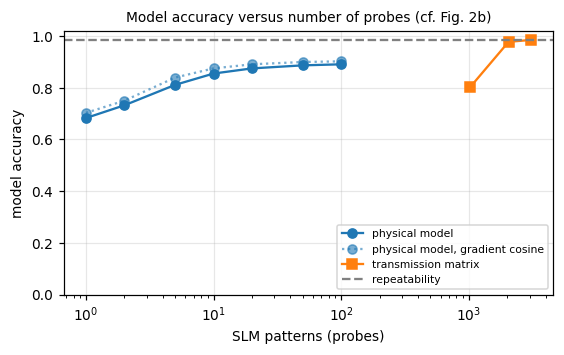

In [5]:
t0 = time.time()
tm, X_tm, Z_tm = tw.measure_tm(bench, rng, 3072, seed_arm=model)
Z_seed = tw.window_fields(model, X_tm)
tm_sizes = [1024, 2048, 3072]
tm_accuracy = [tw.model_accuracy(tw.TMArm(tw.fit_tm(X_tm[:m], Z_tm[:m], Z_seed[:m])), X_held, Y_held, tw.WIN)
               for m in tm_sizes[:-1]] + [tw.model_accuracy(tm, X_held, Y_held, tw.WIN)]
print(f"TM: 3,072 SLM patterns ({time.time() - t0:.0f} s of simulation); model accuracy "
      + ", ".join(f"{m}: {a:.3f}" for m, a in zip(tm_sizes, tm_accuracy)))

fig, ax = plt.subplots(figsize=(5.2, 3.3))
ax.semilogx(ks, sweep["accuracy"], "o-", label="physical model")
ax.semilogx(ks, sweep["cosine"], "o:", color="C0", alpha=0.6, label="physical model, gradient cosine")
ax.semilogx(tm_sizes, tm_accuracy, "s-", color="C1", label="transmission matrix")
ax.axhline(tw.corr(Y_held[0][tw.WIN], bench.read(X_held[0], 10)[tw.WIN]), color="gray", ls="--", label="repeatability")
ax.set_xlabel("SLM patterns (probes)"); ax.set_ylabel("model accuracy"); ax.set_ylim(0, 1.02)
ax.legend(fontsize=7, loc="lower right"); ax.grid(alpha=0.3)
ax.set_title("Model accuracy versus number of probes (cf. Fig. 2b)")
plt.tight_layout(); plt.show()

## 4 · In situ focusing: physical model vs transmission matrix

The loss rewards the intensity in a disk of one speckle grain at the centre, $L = -\langle|\hat O|^2\rangle_\mathrm{disk}$,
so $g = -1/n_\mathrm{disk}$ on the disk. The enhancement is $\eta = \langle I\rangle_\mathrm{disk}/I_0$, with $I_0$ the
mean disk intensity over random patterns. Each loop runs 50 Adam iterations (learning rate 0.1 → 0.03), one SLM
pattern of five exposures per iteration; the final pattern is read ten times. **Both loops use the same measured error
field; only the adjoint differs** (`tw.train_in_situ`).

model (10 probes)    final η = 134.8 ±  6.2 (s.e.m., 10 reads); light in the disk / window = 0.57
TM (3,072 patterns)  final η = 174.7 ±  1.9 (s.e.m., 10 reads); light in the disk / window = 0.67


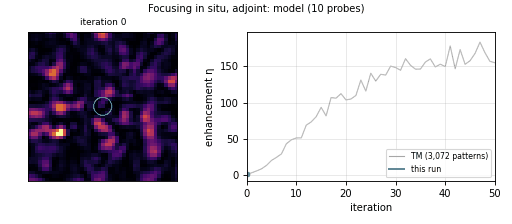

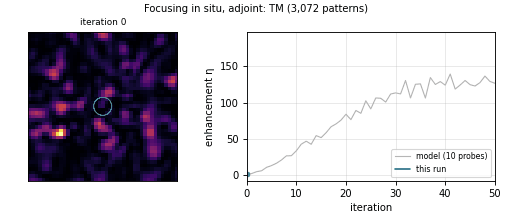

In [6]:
I0 = np.mean(np.abs(bench.read(tw.random_patterns(rng, 320))[:, tw.DISK])**2)
eta = lambda I: I[tw.DISK].mean() / I0
disk = lambda ax: ax.add_patch(Circle((21, 21), 2.6, fill=False, color="cyan", lw=0.8))

ITERS = 50
runs = {"model (10 probes)": tw.train_in_situ(bench, model, tw.focus_loss, eta, iters=ITERS),
        "TM (3,072 patterns)": tw.train_in_situ(bench, tm, tw.focus_loss, eta, iters=ITERS)}
for name, r in runs.items():
    r["eta"] = np.array([eta(I) for I in r["finals"]])
    r["disk_share"] = np.mean([I[tw.DISK].sum() / I[tw.WIN].sum() for I in r["finals"]])
    print(f"{name:20s} final η = {r['eta'].mean():5.1f} ± {r['eta'].std() / np.sqrt(10):4.1f} (s.e.m., 10 reads); "
          f"light in the disk / window = {r['disk_share']:.2f}")

for (name, r), other in zip(runs.items(), list(runs)[::-1]):
    path = f"gifs/focusing_{name.split()[0].lower()}.gif"
    tw.save_gif(path, r["snaps"], r["curve"], "enhancement η", f"Focusing in situ, adjoint: {name}",
                overlay=disk, extra_curves={other: runs[other]["curve"]})
    display(Image(filename=path))

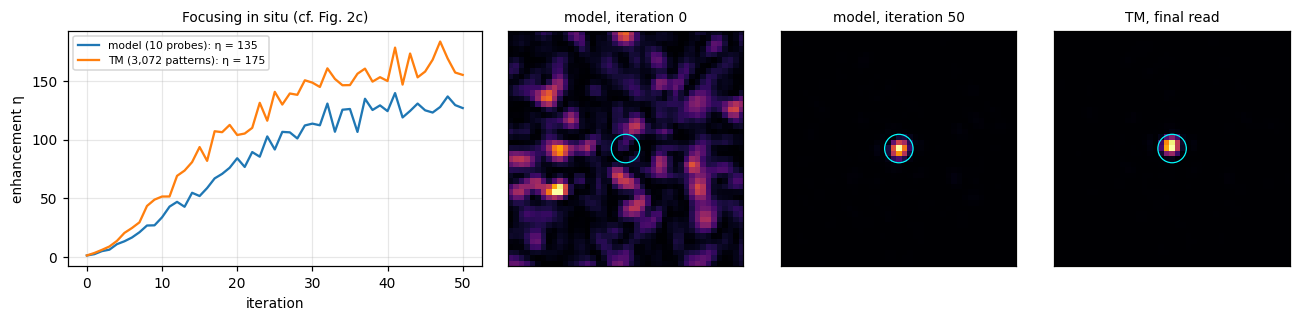

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3), gridspec_kw=dict(width_ratios=[1.6, 1, 1, 1]))
for name, r in runs.items():
    axs[0].plot(r["curve"], label=f"{name}: η = {r['eta'].mean():.0f}")
axs[0].set_xlabel("iteration"); axs[0].set_ylabel("enhancement η"); axs[0].grid(alpha=0.3); axs[0].legend(fontsize=7)
axs[0].set_title("Focusing in situ (cf. Fig. 2c)")
for ax, it in zip(axs[1:3], [0, ITERS]):
    ax.imshow(runs["model (10 probes)"]["snaps"][it], cmap="inferno"); disk(ax)
    ax.set_title(f"model, iteration {it}")
axs[3].imshow(tw.crop_to(runs["TM (3,072 patterns)"]["finals"][0], tw.WIN), cmap="inferno"); disk(axs[3])
axs[3].set_title("TM, final read")
for ax in axs[1:]: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 5 · Single-step focus from each adjoint

Without any loop, the pattern that each adjoint predicts to focus best is the phase of the leading right singular
vector of its rows on the disk (Supplementary Note 3C). The model's rows are obtained by sending every SLM cell through
the model once. Each pattern is then read ten times on the bench.

In [8]:
def single_step_focus(arm):
    rows = []
    for i in range(0, tw.NC**2, 128):
        unit = np.zeros((min(128, tw.NC**2 - i), tw.NC**2), complex)
        unit[np.arange(len(unit)), i + np.arange(len(unit))] = 1
        rows.append(arm.forward(unit.reshape(-1, tw.NC, tw.NC))[:, tw.DISK])
    T_disk = np.concatenate(rows).T                                  # (disk samples, cells)
    v = np.linalg.svd(T_disk, full_matrices=False)[2][0].conj()
    X = np.exp(1j * np.angle(v)).reshape(tw.NC, tw.NC)
    return np.array([eta(np.abs(bench.read(X))**2) for _ in range(10)])

for name, a in [("model (10 probes)", model), ("TM (3,072 patterns)", tm)]:
    e = single_step_focus(a)
    print(f"{name:20s} single-step η = {e.mean():5.1f} ± {e.std() / np.sqrt(10):4.1f}")

model (10 probes)    single-step η = 130.4 ±  5.1
TM (3,072 patterns)  single-step η = 171.0 ±  6.9


## 6 · A stored TM ages; the model is refitted from ten probes

The diffuser is now moved sideways by 50 µm, close to its 60 µm correlation length, hidden from both methods; the
moved screen keeps a correlation of about 0.3 with the original. Re-measuring the TM would cost another 3,072 patterns, so the stored one is kept; the physical model is
refitted, as at the start of every session, from ten new probes, warm-started from the previous screen (Methods).

after the move, model accuracy: stored TM 0.39, stored model 0.34, refitted model 0.85


stored TM       final η =  36.4 ±  1.7


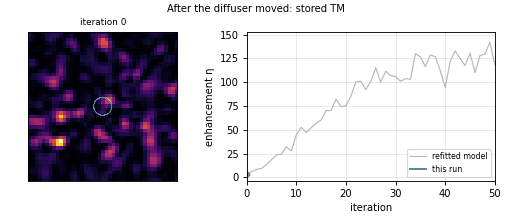

refitted model  final η = 125.8 ±  6.2


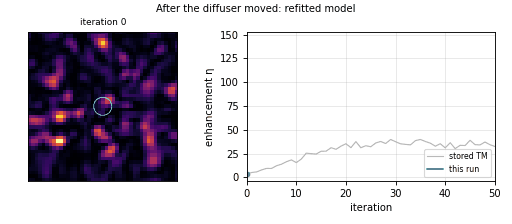

In [9]:
D_start = bench._true.D.copy()                                     # kept for section 7
bench._true.D = tw.shift_screen(bench._true.D, 50e-6)             # the diffuser moves by 50 um (hidden)
Y_held_moved = bench.read(X_held, 10)
X_new = tw.random_patterns(rng, 10)
model_refit = tw.fit_screen(X_new, bench.read(X_new, 5), arm=model)
print(f"after the move, model accuracy: stored TM {tw.model_accuracy(tm, X_held, Y_held_moved, tw.WIN):.2f}, "
      f"stored model {tw.model_accuracy(model, X_held, Y_held_moved, tw.WIN):.2f}, "
      f"refitted model {tw.model_accuracy(model_refit, X_held, Y_held_moved, tw.WIN):.2f}")

moved = {"stored TM": tw.train_in_situ(bench, tm, tw.focus_loss, eta, iters=ITERS),
         "refitted model": tw.train_in_situ(bench, model_refit, tw.focus_loss, eta, iters=ITERS)}
for (name, r), other in zip(moved.items(), list(moved)[::-1]):
    r["eta"] = np.array([eta(I) for I in r["finals"]])
    print(f"{name:15s} final η = {r['eta'].mean():5.1f} ± {r['eta'].std() / np.sqrt(10):4.1f}")
    path = f"gifs/focusing_after_move_{name.replace(' ', '_')}.gif"
    tw.save_gif(path, r["snaps"], r["curve"], "enhancement η", f"After the diffuser moved: {name}",
                overlay=disk, extra_curves={other: moved[other]["curve"]})
    display(Image(filename=path))

## 7 · Focusing while the diffuser drifts slowly

The diffuser now drifts **during** training, with the recipe of the manuscript (Methods, Supplementary Note 5A):

* **Drift.** On the bench, a hidden phase ramp whose frequency grows linearly with the iteration walks the illumination
  across the diffuser, and its output tilt and shift are removed. In the twin, the hidden screen moves under the beam by
  a distance that grows linearly with the iteration, until it has decorrelated to 0.3 at the last iteration (`tw.Drift`),
  the stronger of the two drifts of Supplementary Note 5A.
* **Three runs** from the same ten-probe model: without drift; with drift and a **frozen** model; and with the same drift
  and **refits**, two new random probes and the latest training frame every five iterations, the screen refitted
  (warm-started) on the ten most recent fields.
* **Learning rate** 0.1 → 0.1 in the refitted run, 0.1 → 0.03 in the frozen and drift-free runs (Methods).
* **Score**: the mean η over the last 60 iterations, relative to the drift-free run (bench, at decorrelation 0.3: 17 %
  frozen, 85 % with refits; at 0.5: 48 % and 97 %), and the model accuracy during training, the correlation between each measured training
  frame and the model's prediction (with refits, recent training frames are part of the fit). This score needs runs longer than 60 iterations, so these runs take 150 iterations,
  the number of the manuscript, instead of the 50 used above.

The diffuser first goes back to its state of sections 1–5.

In [10]:
bench._true.D = D_start
DECORRELATION = 0.3
shift = tw.decorrelation_shift(D_start, DECORRELATION)
print(f"the screen decorrelates to {DECORRELATION} after a sideways shift of {shift * 1e6:.1f} µm (60 µm correlation length)")

DRIFT_ITERS = 150
drifts = {"no drift": None,
          "drift, frozen model": tw.Drift(bench, shift, DRIFT_ITERS),
          "drift, refits": tw.Drift(bench, shift, DRIFT_ITERS, refit=True, probes=(X_probe[:10], Y_probe[:10]),
                                    rng=rng)}
drift_runs = {}
for name, drift in drifts.items():
    r = tw.train_in_situ(bench, model, tw.focus_loss, eta, iters=DRIFT_ITERS, final_reads=0,
                         lr_final=0.1 if name == "drift, refits" else 0.03, update=drift)
    if drift:
        drift.reset()
    drift_runs[name] = r
for name, r in drift_runs.items():
    last = r["curve"][-60:].mean()
    print(f"{name:20s} mean η over the last 60 iterations {last:6.1f} "
          f"({100 * last / drift_runs['no drift']['curve'][-60:].mean():3.0f} % of the drift-free run); "
          f"model accuracy at the end {r['accuracy'][-1]:.2f}")
refits = drifts["drift, refits"].refits
print(f"\n{len(refits)} refits, {2 * len(refits)} new probe patterns in all")

for name, r in drift_runs.items():
    path = f"gifs/drift_focusing_{name.replace(', ', '_').replace(' ', '_')}.gif"
    tw.save_gif(path, r["snaps"], r["curve"], "enhancement η", f"focusing, {name}", overlay=disk,
                extra_curves={n: drift_runs[n]["curve"] for n in drift_runs if n != name})

the screen decorrelates to 0.3 after a sideways shift of 51.5 µm (60 µm correlation length)


no drift             mean η over the last 60 iterations  124.9 (100 % of the drift-free run); model accuracy at the end 0.92
drift, frozen model  mean η over the last 60 iterations   42.4 ( 34 % of the drift-free run); model accuracy at the end 0.45
drift, refits        mean η over the last 60 iterations  116.1 ( 93 % of the drift-free run); model accuracy at the end 0.97

30 refits, 60 new probe patterns in all


**GIFs** (files in `gifs/`, linked to keep the notebook small; one frame per iteration):

| no drift | drift, frozen model | drift, refits |
|---|---|---|
| ![no drift](gifs/drift_focusing_no_drift.gif) | ![frozen](gifs/drift_focusing_drift_frozen_model.gif) | ![refits](gifs/drift_focusing_drift_refits.gif) |

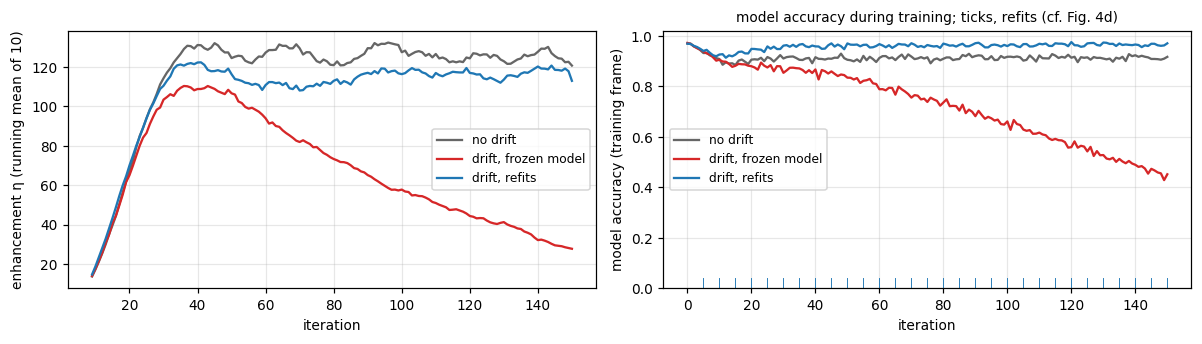

In [11]:
def plot_drift(runs, ylabel, smooth=10):
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.2))
    for (name, r), color in zip(runs.items(), ["0.4", "C3", "C0"]):
        running = np.convolve(r["curve"], np.ones(smooth) / smooth, mode="valid")
        axs[0].plot(np.arange(smooth - 1, len(r["curve"])), running, color=color, label=name)
        axs[1].plot(r["accuracy"], color=color, label=name)
    for it in drifts["drift, refits"].refits:
        axs[1].axvline(it, ymin=0, ymax=0.04, color="C0", lw=0.6)
    axs[0].set_ylabel(f"{ylabel} (running mean of {smooth})"); axs[1].set_ylabel("model accuracy (training frame)")
    axs[1].set_ylim(0, 1.02); axs[1].set_title("model accuracy during training; ticks, refits (cf. Fig. 4d)")
    for ax in axs: ax.set_xlabel("iteration"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()


plot_drift(drift_runs, "enhancement η")

## Summary

SLM patterns spent on the adjoint (Supplementary Table S2) and the focus each adjoint trains. In the twin the free-space
part of the model is known, so no configuration calibration is needed; on the bench it took 50 patterns once.

In [12]:
rows = [("model, 10 probes", 10, sweep["accuracy"][ks.index(10)], runs["model (10 probes)"]["eta"]),
        ("TM, 3N patterns", 3072, tm_accuracy[-1], runs["TM (3,072 patterns)"]["eta"]),
        ("stored TM, after move", 0, tw.model_accuracy(tm, X_held, Y_held_moved, tw.WIN), moved["stored TM"]["eta"]),
        ("model refitted, after move", 10, tw.model_accuracy(model_refit, X_held, Y_held_moved, tw.WIN),
         moved["refitted model"]["eta"])]
print(f"{'adjoint':28s} {'new SLM patterns':>16s} {'model accuracy':>15s} {'final η':>14s}")
for name, p, acc, e in rows:
    print(f"{name:28s} {p:16,d} {acc:15.3f} {e.mean():8.1f} ± {e.std() / np.sqrt(10):3.1f}")
print(f"\nSLM patterns displayed in this notebook: {bench.patterns:,} ({bench.exposures:,} exposures); "
      f"runtime {time.time() - T_START:.0f} s")

adjoint                      new SLM patterns  model accuracy        final η
model, 10 probes                           10           0.855    134.8 ± 6.2
TM, 3N patterns                         3,072           0.985    174.7 ± 1.9
stored TM, after move                       0           0.389     36.4 ± 1.7
model refitted, after move                 10           0.852    125.8 ± 6.2

SLM patterns displayed in this notebook: 4,363 (20,698 exposures); runtime 135 s


**Take-aways.** With an adjoint fitted from ten probes, the measured error field builds the focus within about 40
iterations, as with a TM measured from 3,072 patterns. In the twin, the TM does not drift during its acquisition, so it
predicts held-out fields better than the model (0.99 against 0.86) and trains a higher enhancement; on the bench, where
the medium drifts, both reached η ≈ 100 (Fig. 2c,d). After the diffuser moves by 50 µm, the stored TM predicts held-out
fields with a model accuracy of only 0.39 and focuses to η ≈ 36, whereas ten new probes restore the model (0.85) and the
focus (η ≈ 126). When the diffuser drifts during training to a decorrelation of 0.3, a frozen model keeps only 34 % of
the drift-free focus over the last 60 iterations, whereas refits from two probes and the latest training frame every
five iterations keep 93 % (bench: 17 % and 85 %, Supplementary Note 5A).